In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

Мы будем работать с данными агрегатора такси [Sigma Cabs](https://www.kaggle.com/datasets/arashnic/taxi-pricing-with-mobility-analytics). В зависимости от характеристик поездки требуется предсказать один из трех типов повышенного ценообразования: [1, 2, 3]. Таким образом, это поможет компании оптимально мэтчить такси и клиентов. 

In [2]:
df = pd.read_csv('sigma_cabs.csv')
df.shape

(131662, 14)

In [3]:
# Занесем индекс колонку
df = df.set_index('Trip_ID')
df.head()

,Trip_Distance,Type_of_Cab,Customer_Since_Months,Life_Style_Index,Confidence_Life_Style_Index,Destination_Type,Customer_Rating,Cancellation_Last_1Month,Var1,Var2,Var3,Gender,Surge_Pricing_Type
Trip_ID,,,,,,,,,,,,,
T0005689460,6.77,B,1.0,2.42769,A,A,3.90500,0,40.0,46,60,Female,2
T0005689461,29.47,B,10.0,2.78245,B,A,3.45000,0,38.0,56,78,Male,2
T0005689464,41.58,NaN,10.0,NaN,NaN,E,3.50125,2,NaN,56,77,Male,2
T0005689465,61.56,C,10.0,NaN,NaN,A,3.45375,0,NaN,52,74,Male,3
T0005689467,54.95,C,10.0,3.03453,B,A,3.40250,4,51.0,49,102,Male,2


Описание признаков:

1. **Trip_ID**: ID for TRIP
2. **Trip_Distance**: The distance for the trip requested by the customer
3. **TypeofCab**: Category of the cab requested by the customer
4. **CustomerSinceMonths**: Customer using cab services since n months; 0 month means current month
5. **LifeStyleIndex**: Proprietary index created by Sigma Cabs showing lifestyle of the customer based on their behaviour
6. **ConfidenceLifeStyle_Index**: Category showing confidence on the index mentioned above
7. **Destination_Type**: Sigma Cabs divides any destination in one of the 14 categories.
8. **Customer_Rating**: Average of life time ratings of the customer till date
9. **CancellationLast1Month**: Number of trips cancelled by the customer in last 1 month
10. **Var1**, **Var2** and **Var3**: Continuous variables masked by the company. Can be used for modelling purposes
11. **Gender**: Gender of the customer

**SurgePricingType**: Target (can be of 3 types)


### EDA 
Заполните пропуски в вещественных признаках медианой, а в категориальных - самым популярным классом. Изобразите марицу корреляций и выведите топ5 пар самых коррелированных признаков.

Так как в сумме уникальных значений различных категориальных признаков окажется не супер-много, примените `One-Hot-Encoding` для них. Не забудьте в методе `pd.get_dummies` указать параметр `drop_first=True`.

In [14]:
### Your code is here
cat_cols = df.select_dtypes(include=['object']).columns
num_cols = df.select_dtypes(include=['number']).columns

for col in cat_cols:
    df[col] = df[col].fillna(df[col].value_counts().idxmax())

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

In [19]:
df[num_cols].corr()

,Trip_Distance,Customer_Since_Months,Life_Style_Index,Customer_Rating,Cancellation_Last_1Month,Var1,Var2,Var3,Surge_Pricing_Type
Trip_Distance,1.000000,0.114413,0.468332,-0.054654,-0.007686,-0.031388,0.200456,0.231706,0.135928
Customer_Since_Months,0.114413,1.000000,0.119279,-0.048969,-0.006180,-0.000977,0.041814,0.110851,0.027194
Life_Style_Index,0.468332,0.119279,1.000000,0.189165,0.068188,-0.045710,0.215944,0.303324,-0.073692
Customer_Rating,-0.054654,-0.048969,0.189165,1.000000,0.003595,-0.005398,-0.302968,-0.227531,-0.155279
Cancellation_Last_1Month,-0.007686,-0.006180,0.068188,0.003595,1.000000,0.011711,0.095830,0.128686,0.185646
Var1,-0.031388,-0.000977,-0.045710,-0.005398,0.011711,1.000000,-0.025133,-0.020892,-0.013754
Var2,0.200456,0.041814,0.215944,-0.302968,0.095830,-0.025133,1.000000,0.683437,0.003437
Var3,0.231706,0.110851,0.303324,-0.227531,0.128686,-0.020892,0.683437,1.000000,-0.039309
Surge_Pricing_Type,0.135928,0.027194,-0.073692,-0.155279,0.185646,-0.013754,0.003437,-0.039309,1.000000


In [20]:
def get_redundant_pairs(df):
    '''Получить диагональные и нижние треугольные пары матрицы корреляции'''
    pairs_to_drop = set()
    cols = df.columns
    for i in range(0, df.shape[1]):
        for j in range(0, i + 1):
            pairs_to_drop.add((cols[i], cols[j]))
    return pairs_to_drop

def get_top_abs_correlations(df, n=5):
    # Вычисляем матрицу корреляции по модулю
    au_corr = df.corr().abs().unstack()
    # Находим избыточные пары (диагональ и одну из половин матрицы)
    labels_to_drop = get_redundant_pairs(df)
    # Удаляем их и сортируем по убыванию
    au_corr = au_corr.drop(labels=labels_to_drop).sort_values(ascending=False)
    return au_corr[0:n]

print(get_top_abs_correlations(df[num_cols], 10))

Var2                      Var3                  0.683437
Trip_Distance             Life_Style_Index      0.468332
Life_Style_Index          Var3                  0.303324
Customer_Rating           Var2                  0.302968
Trip_Distance             Var3                  0.231706
Customer_Rating           Var3                  0.227531
Life_Style_Index          Var2                  0.215944
Trip_Distance             Var2                  0.200456
Life_Style_Index          Customer_Rating       0.189165
Cancellation_Last_1Month  Surge_Pricing_Type    0.185646
dtype: float64


In [18]:
df.describe(include=['object'])

,Type_of_Cab,Confidence_Life_Style_Index,Destination_Type,Gender
count,131662,131662,131662,131662
unique,5,3,14,2
top,B,B,A,Male
freq,51346,60548,77597,93900


In [16]:
# df['Type_of_Cab'].value_counts().idxmax()
df.describe()

,Trip_Distance,Customer_Since_Months,Life_Style_Index,Customer_Rating,Cancellation_Last_1Month,Var1,Var2,Var3,Surge_Pricing_Type
count,131662.000000,131662.000000,131662.000000,131662.000000,131662.000000,131662.000000,131662.000000,131662.000000,131662.000000
mean,44.200909,6.015912,2.801448,2.849458,0.782838,62.474883,51.202800,75.099019,2.155747
std,25.522882,3.544411,0.207765,0.980675,1.037559,14.893324,4.986142,11.578278,0.738164
min,0.310000,0.000000,1.596380,0.001250,0.000000,30.000000,40.000000,52.000000,1.000000
25%,24.580000,3.000000,2.687952,2.152500,0.000000,61.000000,48.000000,67.000000,2.000000
50%,38.200000,6.000000,2.798050,2.895000,0.000000,61.000000,50.000000,74.000000,2.000000
75%,60.730000,10.000000,2.912815,3.582500,1.000000,61.000000,54.000000,82.000000,3.000000
max,109.230000,10.000000,4.875110,5.000000,8.000000,210.000000,124.000000,206.000000,3.000000


In [23]:
data = pd.get_dummies(df, drop_first=True, dtype=int)

In [24]:
data.head()

,Trip_Distance,Customer_Since_Months,Life_Style_Index,Customer_Rating,Cancellation_Last_1Month,Var1,Var2,Var3,Surge_Pricing_Type,Type_of_Cab_B,...,Destination_Type_F,Destination_Type_G,Destination_Type_H,Destination_Type_I,Destination_Type_J,Destination_Type_K,Destination_Type_L,Destination_Type_M,Destination_Type_N,Gender_Male
Trip_ID,,,,,,,,,,,,,,,,,,,,,
T0005689460,6.77,1.0,2.42769,3.90500,0,40.0,46,60,2,1,...,0,0,0,0,0,0,0,0,0,0
T0005689461,29.47,10.0,2.78245,3.45000,0,38.0,56,78,2,1,...,0,0,0,0,0,0,0,0,0,1
T0005689464,41.58,10.0,2.79805,3.50125,2,61.0,56,77,2,1,...,0,0,0,0,0,0,0,0,0,1
T0005689465,61.56,10.0,2.79805,3.45375,0,61.0,52,74,3,0,...,0,0,0,0,0,0,0,0,0,1
T0005689467,54.95,10.0,3.03453,3.40250,4,51.0,49,102,2,0,...,0,0,0,0,0,0,0,0,0,1


### Training

In [33]:
np.random.seed(2022)

from sklearn.pipeline import Pipeline

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

X = data.drop('Surge_Pricing_Type', axis=1)
y = data['Surge_Pricing_Type']

In [34]:
y.value_counts()

Surge_Pricing_Type
2    56728
3    47720
1    27214
Name: count, dtype: int64

In [35]:
X_train, X_test, y_train, y_test  = train_test_split(X, y, 
                                                     test_size=0.2, 
                                                     shuffle=True, 
                                                     random_state=2022)

**Задание 1.** Обучите One-vs-Rest Logreg. Не забудьте в шаг добавить стандартизацию данных (через `StandardScaler`) Посчитайте precision, recall, f1-score и усредните по всем классам с помощью micro, macro и weighted avg. Здесь и далее округляйте до 3 знака после запятой.

Чтобы отдельно и долго не вычислять метрики, можно воспользоваться `classification_report` из `sklearn.metrics`!

In [36]:
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

pipe = Pipeline([('scaler', StandardScaler()),
                 ('one_vs_all', OneVsRestClassifier(LogisticRegression()))])

pipe.fit(X_train, y_train)

y_pred = pipe.predict(X_test)

print(classification_report(y_test, y_pred, digits=3))

              precision    recall  f1-score   support

           1      0.723     0.542     0.619      5372
           2      0.636     0.834     0.722     11349
           3      0.741     0.571     0.645      9612

    accuracy                          0.679     26333
   macro avg      0.700     0.649     0.662     26333
weighted avg      0.692     0.679     0.673     26333



Подберите оптимальные гиперпараметры модели с помощью `GridSearchCV()` из предложенных. Для лучшего набора гиперпараметров посчитайте те же самые метрики. Валидировать параметры необходимо по `accuracy`. В этот раз проведем настояющую процедуру Кросс-Валидации! 

Для этого в метод `fit` передадим тренировочную часть наших данных, в параметр `cv` ничего не будем передавать (по дефолту 5-fold Кросс-Валидация будет проведена), а итоговые метрики замерим на тесте!

In [41]:
param_grid = {'one_vs_all__estimator__solver': ['saga'],
    'one_vs_all__estimator__penalty': ['l1', 'l2', 'elasticnet'],
              'one_vs_all__estimator__C': [0.001, 0.01, 0.1, 1],
              'one_vs_all__estimator__l1_ratio': [0.5]}

In [42]:
from sklearn.model_selection import GridSearchCV


### Your code is here
grid_search = GridSearchCV(
    pipe,
    param_grid,
    scoring='accuracy',
    n_jobs=-1,
    error_score='raise',
)
grid_search.fit(X_train, y_train)



,estimator,Pipeline(step...gression()))])
,param_grid,"{'one_vs_all__estimator__C': [0.001, 0.01, ...], 'one_vs_all__estimator__l1_ratio': [0.5], 'one_vs_all__estimator__penalty': ['l1', 'l2', ...], 'one_vs_all__estimator__solver': ['saga']}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,None
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,'raise'
,return_train_score,False
,copy,True


In [43]:
print(f"{grid_search.best_score_:.3f}")

0.681


In [44]:
print(round(grid_search.score(X_test, y_test), 3))

0.681


In [46]:
y_pred_best = grid_search.predict(X_test)
print(f"Лучшие параметры: {grid_search.best_params_}\n")
print(classification_report(y_test, y_pred_best, digits=3))

Лучшие параметры: {'one_vs_all__estimator__C': 0.001, 'one_vs_all__estimator__l1_ratio': 0.5, 'one_vs_all__estimator__penalty': 'l2', 'one_vs_all__estimator__solver': 'saga'}

              precision    recall  f1-score   support

           1      0.742     0.534     0.621      5372
           2      0.635     0.839     0.723     11349
           3      0.742     0.576     0.649      9612

    accuracy                          0.681     26333
   macro avg      0.706     0.650     0.664     26333
weighted avg      0.696     0.681     0.675     26333



Изобразите три калибровочные кривые для Logistic Classifier: 0-vs-rest, 1-vs-rest, 2-vs-rest. Хорошо ли откалиброван обученный классификатор? 

Заметьте, что `predict_proba` возвращает список из вероятностей для всех наших классов!

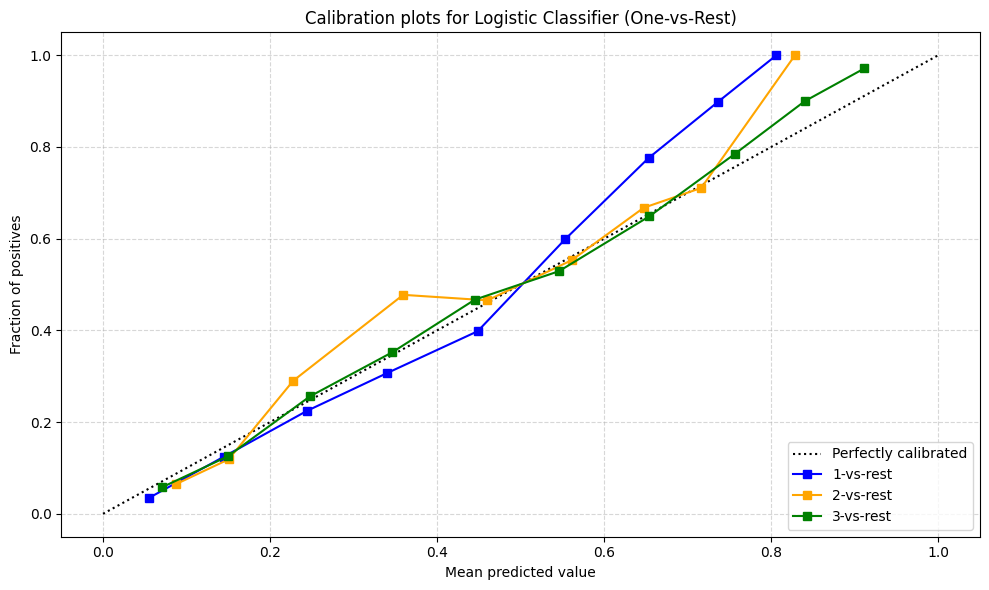

In [53]:
### Your code is here
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

# 1. Получаем предсказания вероятностей для всех 3 классов
prob_pos_multiclass = grid_search.predict_proba(X_test)

plt.figure(figsize=(10, 6))

# Рисуем идеальную линию калибровки
plt.plot([0, 1], [0, 1], "k:", label="Perfectly calibrated")

# Цвета для графиков классов (1, 2, 3)
colors = {1: 'blue', 2: 'orange', 3: 'green'}

# 2. Строим калибровочную кривую для каждого класса (ИСПРАВЛЕНО: итерируемся по)
for class_idx in [1,2,3]:
    # Превращаем y_test в бинарный вектор (1 — текущий класс, 0 — все остальные)
    y_test_bin = (y_test == class_idx).astype(int)
    
    # ВАЖНО: индексы столбцов в predict_proba всегда идут с 0 до 2.
    # Столбец 0 соответствует классу 1, столбец 1 — классу 2, столбец 2 — классу 3.
    prob_class = prob_pos_multiclass[:, class_idx - 1]
    
    # Считаем точки калибровочной кривой
    fraction_of_positives, mean_predicted_value = calibration_curve(
        y_test_bin, 
        prob_class, 
        n_bins=10
    )
    
    # Строим линию на графике
    plt.plot(
        mean_predicted_value, 
        fraction_of_positives, 
        "s-", 
        color=colors[class_idx],
        label=f"{class_idx}-vs-rest"
    )

# Настройка осей и отображения
plt.ylabel("Fraction of positives")
plt.xlabel("Mean predicted value")
plt.ylim([-0.05, 1.05])
plt.xlim([-0.05, 1.05])
plt.legend(loc="lower right")
plt.title('Calibration plots for Logistic Classifier (One-vs-Rest)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Задание 2.** Обучите логистическую регрессию с гиперпараметрами из первого задания на полиномиальных признаках до 4 степени. Сравните метрики с первым заданием.


Пример: Пусть у нас был единственный признак 

$$
d_j = [1, 2, 3, 4]
$$

Тогда полиномиальные признаки до 4 степени от такого будут иметь вид:

$$
d_j^1 = [1, 2, 3, 4]
$$

$$
d_j^2 = [1, 4, 9, 16]
$$

$$
d_j^3 = [1, 8, 27, 64]
$$

$$
d_j^4 = [1, 16, 81, 256]
$$

P.S. Бинарные колонки нет смысла возводить в какие-то степени, поэтому возьмем исключительно вещественные из базовых. 

Для этого можно воспользоваться классическим циклом (или уроком из занятия про `Sberbank Housing Market`). Положите модифицированный датасет в переменную `X_polinomial`!

P.S.S Зачастую еще, создаваю полиномиальные фичи, учитывают "пересечения" признаков, то есть, например, из векторов признаков $d_j, d_i$ генерируют не просто новые степени $d_j^2, d_i^2, d_j^3, d_i^3...$, а еще и признаки вида $d_j \cdot d_i, d_j^2 \cdot d_i, d_j \cdot d_i^2...$, но здесь ограничьтесь просто степенями!

In [56]:
num_cols1 = num_cols[:-1]
num_cols1

Index(['Trip_Distance', 'Customer_Since_Months', 'Life_Style_Index',
       'Customer_Rating', 'Cancellation_Last_1Month', 'Var1', 'Var2', 'Var3'],
      dtype='object')

In [65]:
### Создание полиномиальных признаков

X_polinomial = X.copy()

for col in num_cols1:
    for power in [2, 3, 4]:
        to_add = (X_polinomial[col]**power).to_frame().rename({col:f"{col}_{power}"}, axis=1)
        X_polinomial  = pd.concat((X_polinomial, to_add), axis=1)
### Your code is here

In [66]:
X_pol_train, X_pol_test, y_train, y_test  = train_test_split(X_polinomial, y, 
                                                             test_size=0.2, 
                                                             shuffle=True, 
                                                             random_state=2022)

In [68]:
X_polinomial.head()

,Trip_Distance,Customer_Since_Months,Life_Style_Index,Customer_Rating,Cancellation_Last_1Month,Var1,Var2,Var3,Type_of_Cab_B,Type_of_Cab_C,...,Cancellation_Last_1Month_4,Var1_2,Var1_3,Var1_4,Var2_2,Var2_3,Var2_4,Var3_2,Var3_3,Var3_4
Trip_ID,,,,,,,,,,,,,,,,,,,,,
T0005689460,6.77,1.0,2.42769,3.90500,0,40.0,46,60,1,0,...,0,1600.0,64000.0,2560000.0,2116,97336,4477456,3600,216000,12960000
T0005689461,29.47,10.0,2.78245,3.45000,0,38.0,56,78,1,0,...,0,1444.0,54872.0,2085136.0,3136,175616,9834496,6084,474552,37015056
T0005689464,41.58,10.0,2.79805,3.50125,2,61.0,56,77,1,0,...,16,3721.0,226981.0,13845841.0,3136,175616,9834496,5929,456533,35153041
T0005689465,61.56,10.0,2.79805,3.45375,0,61.0,52,74,0,1,...,0,3721.0,226981.0,13845841.0,2704,140608,7311616,5476,405224,29986576
T0005689467,54.95,10.0,3.03453,3.40250,4,51.0,49,102,0,1,...,256,2601.0,132651.0,6765201.0,2401,117649,5764801,10404,1061208,108243216


In [69]:
### Your code is here

pipe = Pipeline([('scaler', StandardScaler()),
                 ('one_vs_all', OneVsRestClassifier(LogisticRegression()))])

from sklearn.model_selection import GridSearchCV


### Your code is here
grid_search = GridSearchCV(
    pipe,
    param_grid,
    scoring='accuracy',
    n_jobs=-1,
    error_score='raise',
)
grid_search.fit(X_pol_train, y_train)

y_pred_best = grid_search.predict(X_pol_test)
print(f"Лучшие параметры: {grid_search.best_params_}\n")
print(classification_report(y_test, y_pred_best, digits=3))

Лучшие параметры: {'one_vs_all__estimator__C': 0.001, 'one_vs_all__estimator__l1_ratio': 0.5, 'one_vs_all__estimator__penalty': 'l2', 'one_vs_all__estimator__solver': 'saga'}

              precision    recall  f1-score   support

           1      0.748     0.532     0.622      5372
           2      0.636     0.837     0.723     11349
           3      0.741     0.584     0.653      9612

    accuracy                          0.682     26333
   macro avg      0.708     0.651     0.666     26333
weighted avg      0.697     0.682     0.677     26333



По аналогии с первым заданием изобразите три калибровочные кривые. Стало ли лучше?

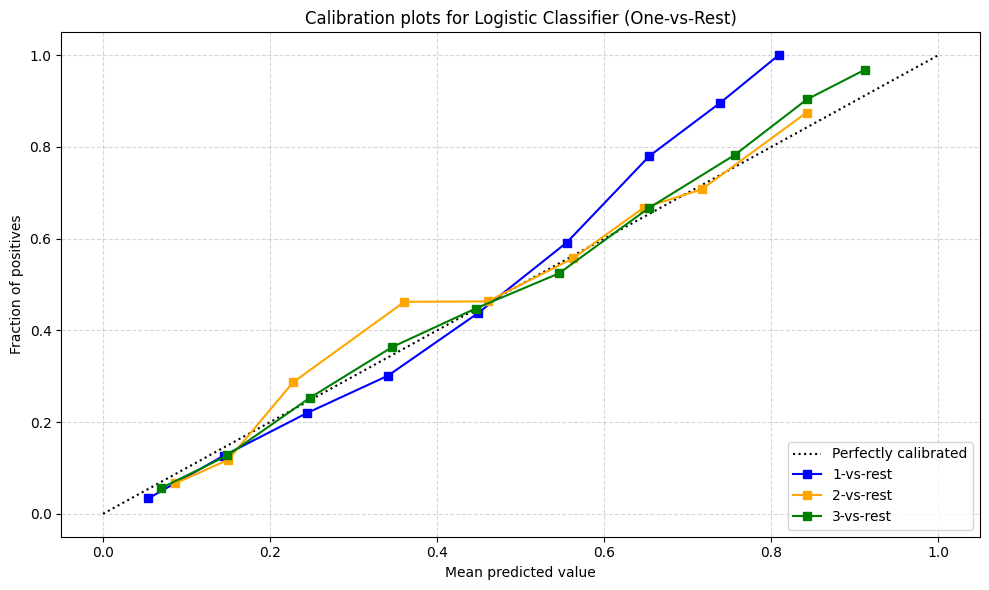

In [71]:
### Your code is here

import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

# 1. Получаем предсказания вероятностей для всех 3 классов
prob_pos_multiclass = grid_search.predict_proba(X_pol_test)

plt.figure(figsize=(10, 6))

# Рисуем идеальную линию калибровки
plt.plot([0, 1], [0, 1], "k:", label="Perfectly calibrated")

# Цвета для графиков классов (1, 2, 3)
colors = {1: 'blue', 2: 'orange', 3: 'green'}

# 2. Строим калибровочную кривую для каждого класса (ИСПРАВЛЕНО: итерируемся по)
for class_idx in [1,2,3]:
    # Превращаем y_test в бинарный вектор (1 — текущий класс, 0 — все остальные)
    y_test_bin = (y_test == class_idx).astype(int)
    
    # ВАЖНО: индексы столбцов в predict_proba всегда идут с 0 до 2.
    # Столбец 0 соответствует классу 1, столбец 1 — классу 2, столбец 2 — классу 3.
    prob_class = prob_pos_multiclass[:, class_idx - 1]
    
    # Считаем точки калибровочной кривой
    fraction_of_positives, mean_predicted_value = calibration_curve(
        y_test_bin, 
        prob_class, 
        n_bins=10
    )
    
    # Строим линию на графике
    plt.plot(
        mean_predicted_value, 
        fraction_of_positives, 
        "s-", 
        color=colors[class_idx],
        label=f"{class_idx}-vs-rest"
    )

# Настройка осей и отображения
plt.ylabel("Fraction of positives")
plt.xlabel("Mean predicted value")
plt.ylim([-0.05, 1.05])
plt.xlim([-0.05, 1.05])
plt.legend(loc="lower right")
plt.title('Calibration plots for Logistic Classifier (One-vs-Rest)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Задание 3.** Обучите на датасете без полиномиальных признаков One-vs-One `SGDClassifier` из `sklearn.linear_model`, который использует стохастический градиентный спуск (узнаете о нем позже) и может обучать как `SVM`, так и, например, `LogReg`, если указать в качестве параметра `loss` либо `hinge`, либо `log` соответственно!

Посчитайте precision, recall, f1-score и усредните по всем классам с помощью micro, macro и weighted avg.

In [72]:
X_train, X_test, y_train, y_test  = train_test_split(X, y, 
                                                     test_size=0.2, 
                                                     shuffle=True, 
                                                     random_state=2022)

In [74]:
from sklearn.linear_model import SGDClassifier
from sklearn.multiclass import OneVsOneClassifier

pipe = Pipeline([('scaler', StandardScaler()),
                 ('one_vs_one', OneVsOneClassifier(SGDClassifier()))])

pipe.fit(X_train,y_train)

y_pred = pipe.predict(X_test)

print(classification_report(y_test, y_pred, digits=3))

              precision    recall  f1-score   support

           1      0.737     0.524     0.612      5372
           2      0.625     0.870     0.728     11349
           3      0.758     0.531     0.625      9612

    accuracy                          0.676     26333
   macro avg      0.707     0.642     0.655     26333
weighted avg      0.697     0.676     0.667     26333



Подберите оптимальные гиперпараметры модели с помощью `GridSearchCV()`. При этом переберите всевозможные функции потерь. Таким образом, при `loss = 'hinge'`, мы обучим SVM, при `loss = 'log'` мы обучим логистическую регрессию и т.д.

Используйте прием с Кросс-Валидацией при подборе параметров, как ранее, а также замерьте метрики на тесте.

In [80]:
param_grid = {'one_vs_one__estimator__loss': ['hinge', 'log_loss', 'modified_huber'],
              'one_vs_one__estimator__penalty': ['l1', 'l2'],
              'one_vs_one__estimator__alpha': [0.001, 0.01, 0.1]}

In [81]:
### Your code is here
pipe = Pipeline([('scaler', StandardScaler()),
                 ('one_vs_one', OneVsOneClassifier(SGDClassifier()))])

grid_search = GridSearchCV(
    pipe,
    param_grid,
    scoring='accuracy',
    n_jobs=-1,
    error_score='raise',
)
grid_search.fit(X_train, y_train)

y_pred_best = grid_search.predict(X_test)
print(f"Лучшие параметры: {grid_search.best_params_}\n")
print(classification_report(y_test, y_pred_best, digits=3))


Лучшие параметры: {'one_vs_one__estimator__alpha': 0.1, 'one_vs_one__estimator__loss': 'modified_huber', 'one_vs_one__estimator__penalty': 'l2'}

              precision    recall  f1-score   support

           1      0.746     0.531     0.620      5372
           2      0.632     0.845     0.723     11349
           3      0.745     0.569     0.646      9612

    accuracy                          0.680     26333
   macro avg      0.708     0.648     0.663     26333
weighted avg      0.697     0.680     0.674     26333



Можно ли однозначно сказать, какой подход оказался лучше: One-vs-Rest или One-vs-One?